# 04 - Accretion History (~5 Myr → 100 Myr)

This notebook reconstructs the post-gas-disk accretion history of planetary embryos using N-body simulation data and collision records. It contains no element-partition calculation, so the same collision-tree logic applies to the sulfur workflow.

It covers:
- Loading N-body simulation snapshots and identifying final planets (m ≥ 0.01 M⊕)
- Tracking mass evolution of each planet across all time steps
- Loading collision records and filtering events **after** the gas disk phase (t > 5 Myr)
- Tracing full collision histories using `CollisionTracer` for each planet
- Visualizing planet mass evolution (full simulation & post-gas-disk) with bubble-size scatter plots
- Exporting collision history tables for the later sulfur-bearing impact and differentiation steps

> **Workflow context:** `B_01_embryo_bulk_composition_s.ipynb` provides the 5 Myr particle compositions (`S`, `S_sil`, and `S_met` included). This notebook independently provides the post-disk collision trees; a later module joins them by particle ID.  
> **Input:** `notebooks/N_body_dataset/<model>/aei*` snapshots and the corresponding `Collision*` file  
> **Output:** `notebooks/work_flow_S/Tables/04_accretion_history_S.xlsx`

Run from the project root or `notebooks/work_flow_S`.


In [1]:
# Final planets are sorted by increasing final semi-major axis a.
PROJECT_ROOT = None
WORKFLOW_DIR = None
MODEL_ID = 'simF_01'
MODEL_DIR = None
GAS_TIME = '5.0 Myr'
PLANET_MASS_THRESHOLD = 0.01  # M Earth; selects planets for all subsequent stages
OUTPUT_HISTORY_FILE = None
OUTPUT_ORDER_FILE = None


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys
import matplotlib.patches as mpatches
from pathlib import Path

working_dir = Path.cwd()
project_root = (Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT is not None
                else next((p for p in (working_dir, *working_dir.parents)
                           if (p / "src" / "accrediff").is_dir()), None))
if project_root is None:
    raise RuntimeError("Could not locate the AccreDiff repository root.")
workflow_dir = (Path(WORKFLOW_DIR).expanduser().resolve() if WORKFLOW_DIR is not None
                else project_root / 'kong_2027_backup' / 'work_flow_S')

sys.path.insert(0, str(project_root / 'src'))
import accrediff as ad


# ── Plot style ──────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": False,
    "ytick.right": False,
    "figure.dpi": 150,
    "xtick.major.size": 8,
    "xtick.minor.size": 5,
    "xtick.major.width": 1.3,
    "xtick.minor.width": 1.0,
})

print(f"Project root : {project_root}")
print("Setup complete.")


Project root : /Users/kong/Research/code_zju/AccreDiff
Setup complete.


## 1. Load N-body Simulation Data

Read all `aei` snapshot files from the selected model directory.  
Each snapshot contains orbital elements and masses for all particles at a given time step (0.1 Myr interval).

- Mass is converted from solar units to Earth mass units (`m_e = m / ME`)
- Particle index `i` is used as the DataFrame index for cross-snapshot tracking

In [3]:
# ── Model selection ──────────────────────────────────────
model = MODEL_ID
model_dir = Path(MODEL_DIR) if MODEL_DIR is not None else project_root / 'notebooks' / 'N_body_dataset' / model
if not model_dir.is_dir():
    raise FileNotFoundError(f'N-body model directory not found: {model_dir}')

# ── Load all aei snapshots ───────────────────────────────
file_paths = sorted(path for path in model_dir.iterdir() if path.name.startswith('aei'))
if not file_paths:
    raise FileNotFoundError(f'No aei snapshots found in {model_dir}')
keys = [f'{i/10:.1f} Myr' for i in range(len(file_paths))]

col_names = ['t', 'i', 'a', 'e', 'inc', 'Omega', 'w', 'T', 'E', 'M', 'm', 'r']
A_dict = {}
for path, key in zip(file_paths, keys):
    A_dict[key] = pd.read_csv(
        path, sep=r'\s+', header=None, names=col_names, index_col='i'
    )

# Convert mass to Earth units
for key in A_dict:
    A_dict[key]['m_e'] = A_dict[key]['m'] / ad.constants.ME
    A_dict[key]['N']   = len(A_dict[key])

print(f"Model     : {model}")
print(f"Snapshots : {len(A_dict)}")
print(f"Time range: {list(A_dict.keys())[0]} → {list(A_dict.keys())[-1]}")


Model     : simF_01
Snapshots : 2001
Time range: 0.0 Myr → 200.0 Myr


## 2. Identify Final Planets (t = 100 Myr)

Planets are defined as particles with mass ≥ 0.01 M⊕ at the **final** simulation snapshot.  
The two giant planets (index 0 and 1) are excluded.  
Planets are sorted by final semi-major axis `a` (ascending, inner to outer) and assigned sequential IDs (`planets_1`, `planets_2`, ...).

In [4]:
planet_mass_threshold = PLANET_MASS_THRESHOLD
time_end = keys[-1]
# time_end = '118.0 Myr'  # Optional override when a different final snapshot is required.
df_end = A_dict[time_end][['a', 'e', 'inc', 'm_e']].iloc[2:]  # remove giant planets
df_planet = (
    df_end[df_end['m_e'] >= planet_mass_threshold]
    .sort_values(['a', 'm_e'], ascending=[True, False], kind='mergesort')
)
if not np.isfinite(df_planet[['a', 'm_e']].to_numpy(dtype=float)).all():
    raise ValueError('Final planets must have finite semi-major axes and masses.')
if (df_planet['a'] <= 0.0).any():
    raise ValueError('Final planet semi-major axes must be positive.')
planets_index = df_planet.index.tolist()
keys_planets  = [f'planets_{i+1}' for i in range(len(planets_index))]
planet_order = pd.DataFrame({
    'planet': keys_planets,
    'final_particle_id': planets_index,
    'a_final_au': df_planet['a'].to_numpy(dtype=float),
    'm_e_final': df_planet['m_e'].to_numpy(dtype=float),
})

print(f"Final snapshot          : {time_end}")
print(f"Planet mass threshold   : {planet_mass_threshold:.2f} M⊕")
print(f"Planets found           : {len(planets_index)}")
planet_order


Final snapshot          : 200.0 Myr
Planet mass threshold   : 0.01 M⊕
Planets found           : 6


,planet,final_particle_id,a_final_au,m_e_final
0,planets_1,316,0.713129,0.586986
1,planets_2,165,0.921611,0.351988
2,planets_3,678,1.216084,0.711395
3,planets_4,1948,1.590414,0.146963
4,planets_5,724,1.953605,0.038836
5,planets_6,1103,2.387254,0.038831


In [5]:
df_planet.sum()

a      8.782097
e      0.396195
inc    0.263552
m_e    1.875000
dtype: float64

## 3. Track Mass Evolution Across All Snapshots

For each time step, extract the semi-major axis (`a`) and mass (`m_e`) of each identified planet.  
Results are stored in `df_history` with columns `a_1`, `m_1`, `a_2`, `m_2`, ...  
A `Time` column (in Myr) is added for plotting.  
Particles that have been ejected or merged at a given snapshot are filled with `NaN`.

In [6]:
columns    = [f'{prefix}_{i+1}' for i in range(len(planets_index)) for prefix in ('a', 'm')]
df_history = pd.DataFrame(columns=columns)

for t in A_dict.keys():
    df_snap = A_dict[t][['a', 'm_e']].iloc[2:]
    planets = df_snap.reindex(planets_index)[['a', 'm_e']]
    df_history.loc[len(df_history)] = planets.values.flatten().tolist()

df_history['Time'] = [float(k.replace(' Myr', '')) for k in A_dict.keys()]
df_history = df_history.astype(float)

print(f"df_history shape: {df_history.shape}")
df_history.head()

df_history shape: (2001, 13)


,a_1,m_1,a_2,m_2,a_3,m_3,a_4,m_4,a_5,m_5,a_6,m_6,Time
0,0.950760,0.000694,1.022242,0.000829,1.036573,0.000957,1.027593,0.000855,1.049597,0.000820,0.820597,0.000999,0.0
1,1.001956,0.004721,1.051239,0.005951,1.036736,0.003904,1.096249,0.003129,0.984518,0.002578,0.829436,0.000999,0.1
2,0.973971,0.005711,0.919498,0.015591,1.004486,0.006366,1.172108,0.006949,0.996720,0.002578,0.810987,0.001992,0.2
3,0.910459,0.005711,0.944278,0.052716,0.964583,0.006366,1.156879,0.009249,1.003249,0.003178,0.810510,0.002957,0.3
4,0.813793,0.005711,0.891613,0.071544,1.042970,0.013761,1.184318,0.012847,0.980977,0.003178,0.812323,0.006452,0.4


## 4. Visualize Mass Evolution (Full Simulation: 0 → 100 Myr)

Plot mass evolution of each planet over the full simulation.  
- Dashed lines connect snapshots
- Scatter markers appear every 5 Myr; marker size scales with planet mass
- The gas disk end time (5 Myr) is marked with a vertical dashed line

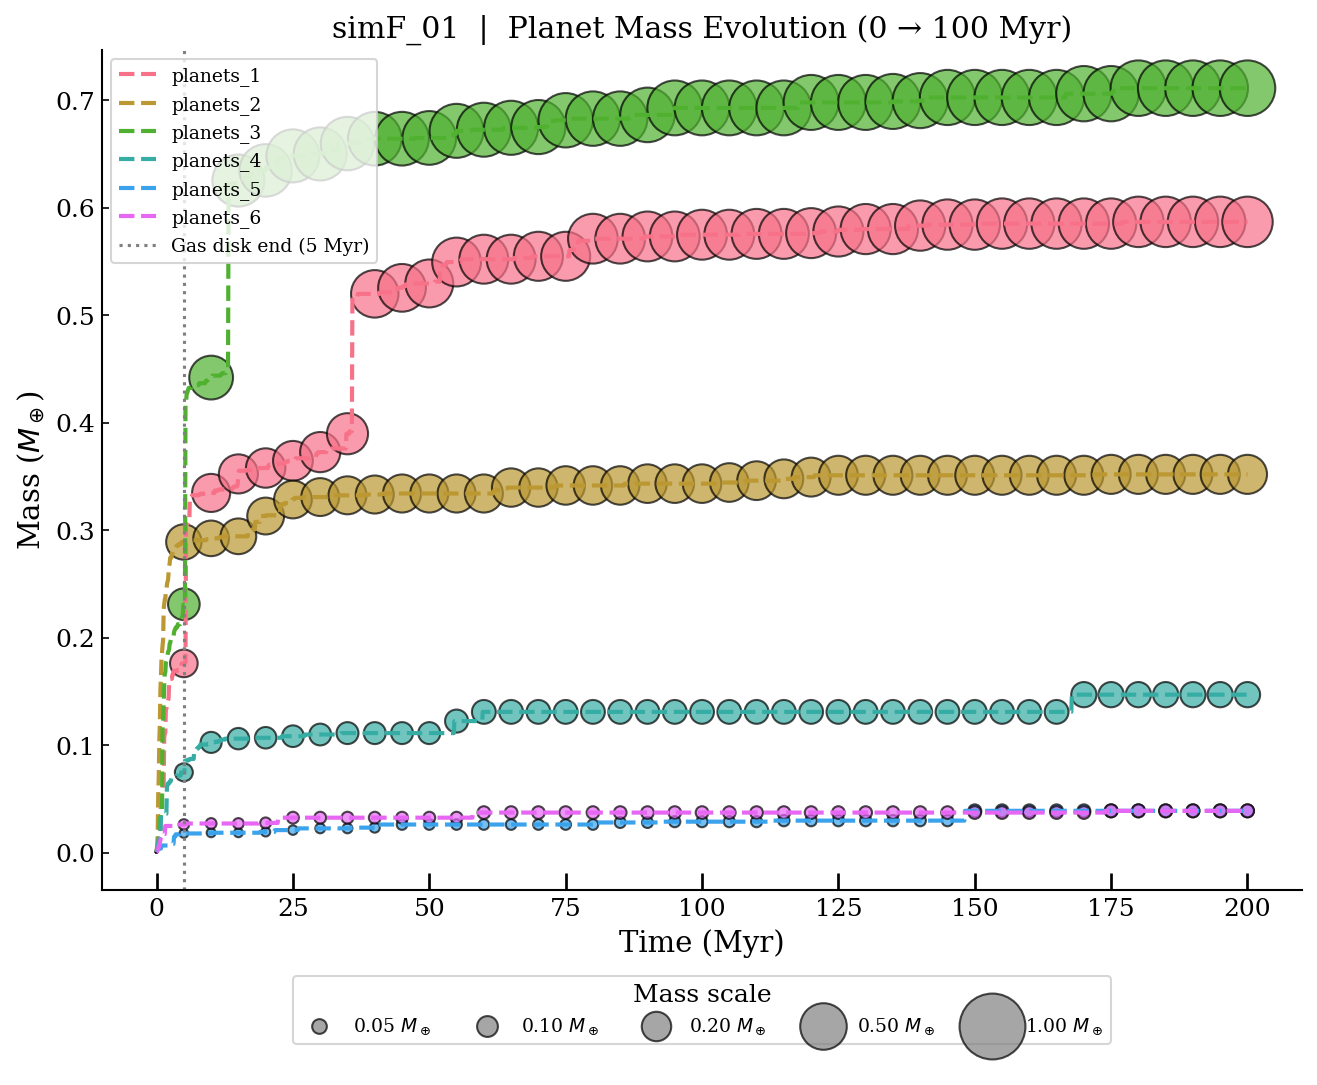

In [7]:
m_cols = [col for col in df_history.columns if col.startswith('m_')]
colors = sns.color_palette("husl", n_colors=len(m_cols))

fig = plt.figure(figsize=(10, 8))
ax  = fig.add_axes([0.1, 0.2, 0.8, 0.7])

for i, col in enumerate(m_cols):
    ax.plot(df_history['Time'], df_history[col],
            linestyle='--', linewidth=2, color=colors[i], label=keys_planets[i])
    mask = (np.round(df_history['Time'] % 5, 6) == 0)
    ax.scatter(df_history['Time'][mask], df_history[col][mask],
               s=df_history[col][mask] * 1000,
               color=colors[i], alpha=0.7, edgecolors='k')

ax.axvline(5.0, color='gray', linestyle=':', linewidth=1.5, label='Gas disk end (5 Myr)')
ax.set_xlabel('Time (Myr)')
ax.set_ylabel('Mass ($M_\\oplus$)')
ax.set_title(f'{model}  |  Planet Mass Evolution (0 → 100 Myr)')
ax.legend(loc='upper left', fontsize=9, frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── Mass size legend ─────────────────────────────────────
sizes   = [0.05, 0.10, 0.20, 0.50, 1.00]
handles = [plt.scatter([], [], s=s*1000, color='gray', alpha=0.7, edgecolors='k') for s in sizes]
labels  = [f'{s:.2f} $M_\\oplus$' for s in sizes]
legend_ax = fig.add_axes([0.1, 0.05, 0.8, 0.10])
legend_ax.axis('off')
legend_ax.legend(handles, labels, loc='center', ncol=len(sizes),
                 frameon=True, title='Mass scale', fontsize=9)

plt.show()

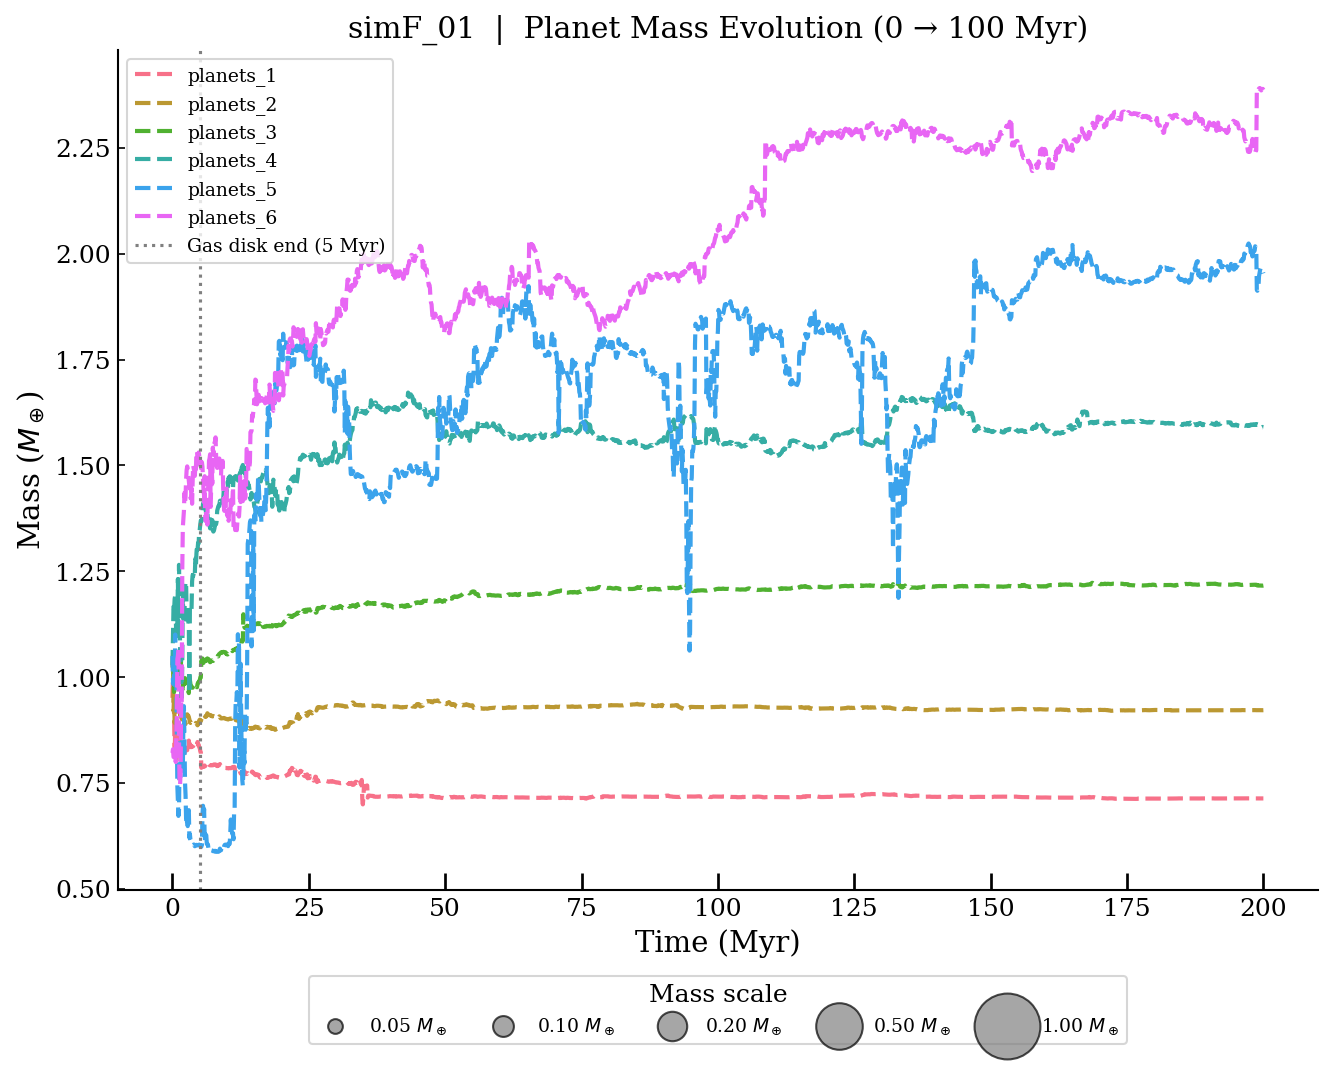

In [8]:
m_cols = [col for col in df_history.columns if col.startswith('a_')]
colors = sns.color_palette("husl", n_colors=len(m_cols))

fig = plt.figure(figsize=(10, 8))
ax  = fig.add_axes([0.1, 0.2, 0.8, 0.7])

for i, col in enumerate(m_cols):
    ax.plot(df_history['Time'], df_history[col],
            linestyle='--', linewidth=2, color=colors[i], label=keys_planets[i])
    mask = (np.round(df_history['Time'] % 5, 6) == 0)
ax.axvline(5.0, color='gray', linestyle=':', linewidth=1.5, label='Gas disk end (5 Myr)')
ax.set_xlabel('Time (Myr)')
ax.set_ylabel('Mass ($M_\\oplus$)')
ax.set_title(f'{model}  |  Planet Mass Evolution (0 → 100 Myr)')
ax.legend(loc='upper left', fontsize=9, frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── Mass size legend ─────────────────────────────────────
sizes   = [0.05, 0.10, 0.20, 0.50, 1.00]
handles = [plt.scatter([], [], s=s*1000, color='gray', alpha=0.7, edgecolors='k') for s in sizes]
labels  = [f'{s:.2f} $M_\\oplus$' for s in sizes]
legend_ax = fig.add_axes([0.1, 0.05, 0.8, 0.10])
legend_ax.axis('off')
legend_ax.legend(handles, labels, loc='center', ncol=len(sizes),
                 frameon=True, title='Mass scale', fontsize=9)

plt.show()

## 5. Load Collision Records & Filter Post-Gas-Disk Phase

Collision events are read from the `Collision` file.  
Only collisions occurring **after** the gas disk lifetime (t > 5 Myr) are retained for post-disk accretion analysis.  
`ad.resolve_product_id()` determines which particle survives each collision event.

In [9]:
# ── Locate collision file ────────────────────────────────
collision_files = sorted(
    path for path in model_dir.iterdir() if path.name.startswith('Collision')
)
if not collision_files:
    raise FileNotFoundError(f'No Collision file found in {model_dir}')
if len(collision_files) > 1:
    raise RuntimeError(
        f'Expected one Collision file in {model_dir}, found {len(collision_files)}.'
    )

col_names_c = [
    'time',
    'indexi', 'mi', 'ri', 'xi', 'yi', 'zi', 'vxi', 'vyi', 'vzi', 'Sxi', 'Syi', 'Szi',
    'indexj', 'mj', 'rj', 'xj', 'yj', 'zj', 'vxj', 'vyj', 'vzj', 'Sxj', 'Syj', 'Szj',
]

# Sxi/Syi/Szi and Sxj/Syj/Szj are spin-vector fields, not sulfur abundances.
C_data = pd.read_csv(collision_files[0], sep=r'\s+', header=None, names=col_names_c)
C_data['m_ei'] = C_data['mi'] / ad.constants.ME
C_data['m_ej'] = C_data['mj'] / ad.constants.ME

# Filter: post-gas-disk only
gas_time = GAS_TIME
gas_time_yr = A_dict[gas_time]['t'].iloc[0]
C_nogas     = C_data[C_data['time'] > gas_time_yr].copy()
C_nogas['product_id'] = C_nogas.apply(ad.resolve_product_id, axis=1)

collision_df = (
    C_nogas[['time', 'indexi', 'm_ei', 'indexj', 'm_ej', 'product_id']]
    .sort_values('time')
    .reset_index(drop=True)
)

print(f"Gas disk end      : {gas_time_yr:.0f} yr")
print(f"Collision file    : {collision_files[0]}")
print(f"Total collisions  : {len(C_data)}")
print(f"Post-disk         : {len(collision_df)}")
collision_df.head()


Gas disk end      : 4928131 yr
Collision file    : /Users/kong/Research/code_zju/AccreDiff/notebooks/N_body_dataset/simF_01/CollisionssimF_01.dat
Total collisions  : 2482
Post-disk         : 460


,time,indexi,m_ei,indexj,m_ej,product_id
0,5.030795e+06,2172,0.000683,2222,0.000675,2172.0
1,5.066586e+06,1918,0.159169,1476,0.001714,1918.0
2,5.075214e+06,316,0.176045,868,0.000804,316.0
3,5.081401e+06,1948,0.074662,450,0.000652,1948.0
4,5.083152e+06,1948,0.075315,1167,0.000564,1948.0


## 6. Trace Full Collision Histories

`CollisionTracer.trace_full_history()` reconstructs the complete merger tree for each final planet,
returning every collision event in its ancestry chain.

Results are stored in `dict_history` keyed by planet ID (`planets_1`, `planets_2`, ...).  
Each entry contains:
- `time` — collision time (yr)
- `Time` — collision time (Myr)
- `indexi`, `indexj` — colliding particle indices
- `m_ei`, `m_ej` — masses at collision (M⊕)
- `Mass` — total mass of the collision event (`m_ei + m_ej`)
- `product_id` — surviving particle index

In [10]:
tracer       = ad.CollisionTracer(collision_df)
dict_history = {}

for key, index in zip(keys_planets, planets_index):
    h = tracer.trace_full_history(index)
    h['Time'] = h['time'] / 1e6
    h['Mass'] = h['m_ei'] + h['m_ej']
    dict_history[key] = h

print("Collision history tracing complete.")
dict_history[keys_planets[0]].head()

Collision history tracing complete.


,time,indexi,m_ei,indexj,m_ej,product_id,Time,Mass
0,5.075214e+06,316,0.176045,868,0.000804,316,5.075214,0.176849
1,5.230915e+06,316,0.176849,1345,0.128717,316,5.230915,0.305566
2,5.543898e+06,2085,0.001019,2042,0.000946,2085,5.543898,0.001966
3,5.606396e+06,316,0.305566,1548,0.000626,316,5.606396,0.306192
4,5.629362e+06,316,0.306192,958,0.000870,316,5.629362,0.307061


## 7. Visualize Post-Gas-Disk Accretion Events

For each planet, plot only the collision events where that planet is the **product** (`product_id == index`).  
- X-axis: collision time (log scale, Myr)
- Y-axis: total mass at collision event (M⊕)
- Marker size scales with mass

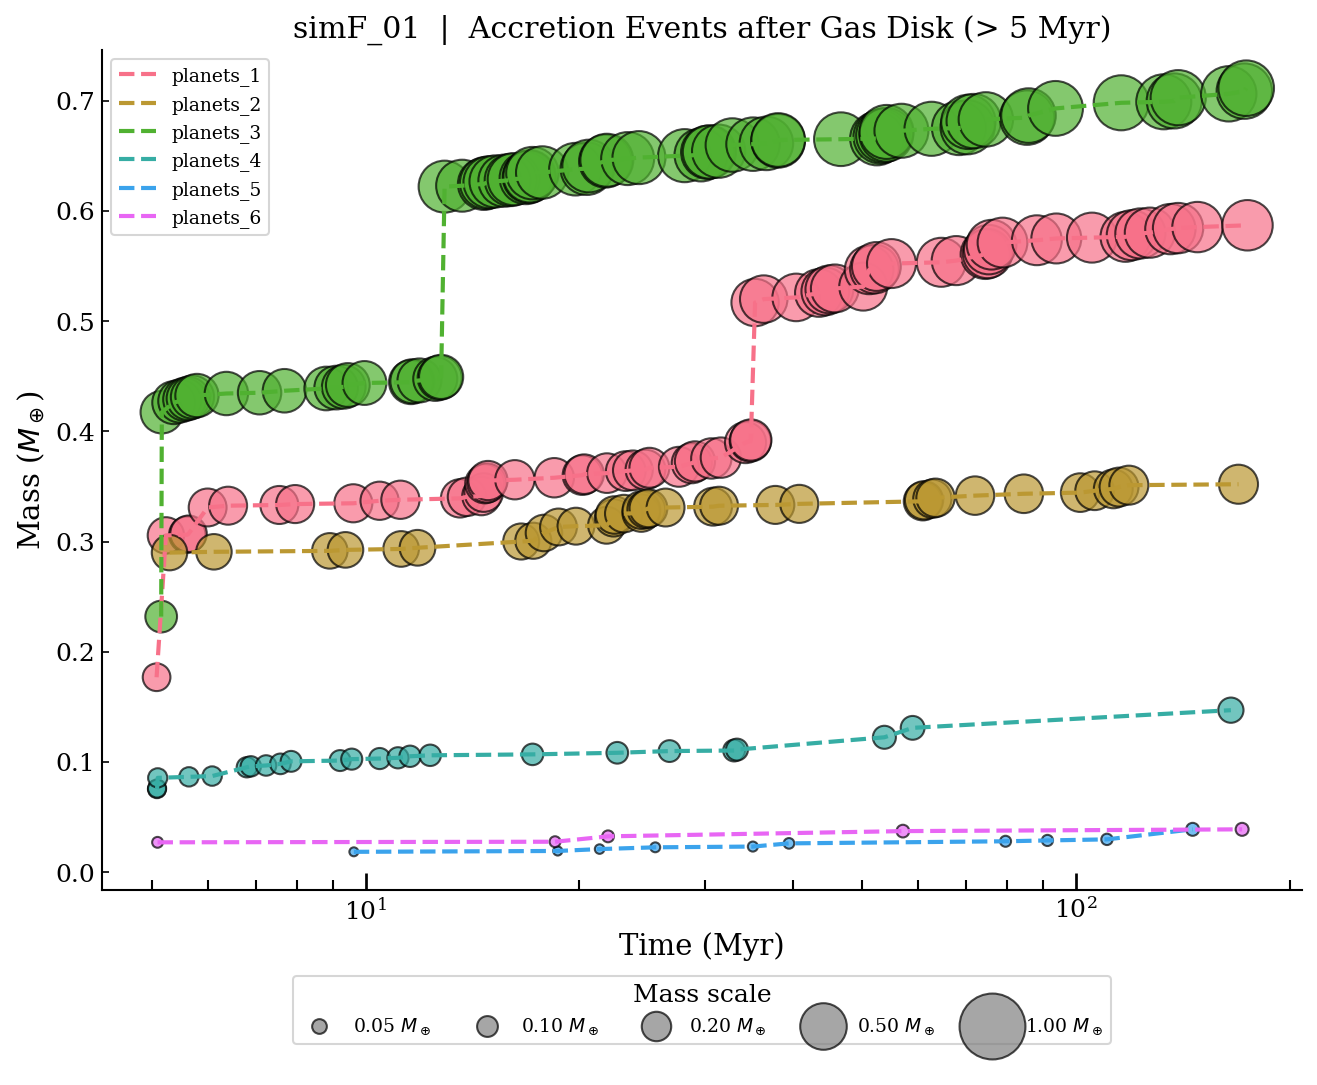

In [11]:
colors = sns.color_palette("husl", n_colors=len(keys_planets))

fig = plt.figure(figsize=(10, 8))
ax  = fig.add_axes([0.1, 0.2, 0.8, 0.7])

for i, (key, index) in enumerate(zip(keys_planets, planets_index)):
    df_p = dict_history[key][dict_history[key]['product_id'] == index]
    x, y = df_p['Time'], df_p['Mass']
    ax.plot(x, y, linestyle='--', linewidth=2, color=colors[i], label=key)
    ax.scatter(x, y, s=y * 1000, color=colors[i], alpha=0.7, edgecolors='k')

ax.set_xscale('log')
ax.set_xlabel('Time (Myr)')
ax.set_ylabel('Mass ($M_\\oplus$)')
ax.set_title(f'{model}  |  Accretion Events after Gas Disk (> 5 Myr)')
ax.legend(loc='upper left', fontsize=9, frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── Mass size legend ─────────────────────────────────────
sizes   = [0.05, 0.10, 0.20, 0.50, 1.00]
handles = [plt.scatter([], [], s=s*1000, color='gray', alpha=0.7, edgecolors='k') for s in sizes]
labels  = [f'{s:.2f} $M_\\oplus$' for s in sizes]
legend_ax = fig.add_axes([0.1, 0.05, 0.8, 0.10])
legend_ax.axis('off')
legend_ax.legend(handles, labels, loc='center', ncol=len(sizes),
                 frameon=True, title='Mass scale', fontsize=9)

plt.show()

## 8. Export Collision Histories to Excel

Save each planet's full collision history as a separate sheet. The sulfur-specific filename prevents accidental reuse of the sulfur-free workflow output.

**Outputs:** `notebooks/work_flow_S/Tables/04_accretion_history_S.xlsx` and `04_planet_order_S.csv`. The latter preserves the final particle ID and semi-major axis behind each Planet label.


In [12]:
save_dir = workflow_dir / 'Tables'
save_dir.mkdir(parents=True, exist_ok=True)

order_file = Path(OUTPUT_ORDER_FILE) if OUTPUT_ORDER_FILE is not None else save_dir / '04_planet_order_S.csv'
planet_order.to_csv(order_file, index=False)
save_file = Path(OUTPUT_HISTORY_FILE) if OUTPUT_HISTORY_FILE is not None else save_dir / '04_accretion_history_S.xlsx'
with pd.ExcelWriter(save_file) as writer:
    for key, df in dict_history.items():
        df.to_excel(writer, sheet_name=key, index=False)

print(f"Saved: {save_file}")
print(f"Planet order: {order_file}")

# Verify that every collision tree was written and can be read back.
exported_history = pd.read_excel(save_file, sheet_name=None)
assert list(exported_history) == list(dict_history)
exported_order = pd.read_csv(order_file)
assert exported_order['planet'].tolist() == list(dict_history)
assert exported_order['final_particle_id'].tolist() == planets_index
assert exported_order['a_final_au'].is_monotonic_increasing
print(f"Sheets: {list(exported_history)}")


Saved: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/04_accretion_history_S.xlsx
Planet order: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/04_planet_order_S.csv
Sheets: ['planets_1', 'planets_2', 'planets_3', 'planets_4', 'planets_5', 'planets_6']


## 9. Summary

| Step | Operation | Output |
|------|-----------|--------|
| 1 | Load N-body snapshots | `A_dict` |
| 2 | Identify final planets (m ≥ 0.01 M⊕) | `df_planet`, `planets_index` |
| 3 | Track mass evolution across all snapshots | `df_history` |
| 4 | Visualize full mass evolution (0 → 100 Myr) | line + bubble plot |
| 5 | Load and filter post-disk collision records | `collision_df` |
| 6 | Trace full collision histories | `dict_history` |
| 7 | Visualize post-disk accretion events | log-scale bubble plot |
| 8 | Export sulfur-workflow collision trees | `Tables/04_accretion_history_S.xlsx`, `Tables/04_planet_order_S.csv` |

This notebook records collision ancestry only. Sulfur-bearing phase compositions remain in `Tables/03_embryo_bulk_composition.csv` and will be joined to these histories by particle ID in the later impact/differentiation workflow.

➡️ **Next:** construct the sulfur-aware impact-event table from the 03 compositions and the 04 collision trees.
